In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

# =========================================================================
# CONFIGURATION
# =========================================================================
EPOCHS = 75                 
BATCH_SIZE = 128            
PATCH_SIZE = 64
TEMPORAL_WINDOW = 11        # We grab 11 frames (Target is index 5)
NUM_WORKERS = 4             
PATCHES_PER_STACK = 5000    

# --- CRITICAL FOR SELF-SUPERVISED ---
# Input channels = Window - 1 (Because we remove the center frame)
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames

# DEVICE SETUP
if torch.cuda.is_available():
    DEVICE = torch.device("cuda:0") 
    print(f"Running on Single GPU: {torch.cuda.get_device_name(0)}")
else:
    DEVICE = torch.device("cpu")

TRAIN_DIR = "/kaggle/input/dataset/dataset1/Train" # <--- VERIFY THIS PATH

def list_clean_tiffs(folder):
    return sorted([
        os.path.join(folder, f) for f in os.listdir(folder)
        if f.endswith(".tif") and not f.startswith("._")
    ])

train_files = list_clean_tiffs(TRAIN_DIR)

# =========================================================================
# 1. DATASET: SELF-SUPERVISED (BLIND SPOT)
# =========================================================================
class CalciumDataset(Dataset):
    def __init__(self, files, patch_size=64, window=11, patches_per_stack=400, mode='2.5D'):
        self.files = files
        self.patch_size = patch_size
        self.window = window
        self.half = window // 2
        self.patches_per_stack = patches_per_stack
        self.mode = mode
        
        # --- PRELOAD DATA INTO RAM ---
        print(f"Loading {len(files)} TIFF stacks into RAM... (Mode: {mode})")
        self.data_cache = []
        for f in files:
            img = tifffile.imread(f).astype(np.float32)
            img = img / (img.max() + 1e-8)
            self.data_cache.append(img)
        print("Data loaded successfully!")

    def __len__(self):
        return len(self.files) * self.patches_per_stack

    def __getitem__(self, idx):
        file_idx = idx // self.patches_per_stack
        stack = self.data_cache[file_idx]
        F_tot, H, W = stack.shape
        
        # Random Crop
        t = random.randint(self.half, F_tot - self.half - 1)
        y = random.randint(0, H - self.patch_size)
        x = random.randint(0, W - self.patch_size)

        # Extract full window (e.g., 11 frames)
        full_window = stack[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC ---
        # Target is the center frame
        tgt_slice = full_window[self.half].copy() 
        
        # Input is everything EXCEPT the center frame
        # Concatenate frames [0..4] and [6..10]
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)

        if self.mode == '3D':
            # Input: (1, 10, H, W) | Target: (1, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float() 
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float() 
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W) | Target: (1, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float() 
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

# =========================================================================
# 2. ViT-UNet
# =========================================================================
class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out

# =========================================================================
# TRAINING LOOP (WITH SAVE FUNCTIONALITY)
# =========================================================================
def train_model(model_name, model, loader, epochs=EPOCHS):
    print(f"\n>>> Training {model_name}...")
    model = model.to(DEVICE)
    
    if torch.cuda.device_count() > 1:
        model = nn.DataParallel(model)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    criterion = nn.MSELoss()
    scaler = amp.GradScaler()
    
    best_loss = float('inf') # Track best loss

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        loop = tqdm(loader, desc=f"Epoch {epoch+1}/{epochs}")
        
        for inputs, targets in loop:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            
            optimizer.zero_grad()
            
            with amp.autocast():
                outputs = model(inputs)
                
                if model_name == "DeepCAD":
                    # DeepCAD outputs (B, 1, 10, H, W). Target is (B, 1, H, W).
                    # We average the temporal output to estimate the single missing frame
                    outputs = outputs.mean(dim=2) 
                
                loss = criterion(outputs, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            epoch_loss += loss.item()
            loop.set_postfix(loss=loss.item())
        
        avg_loss = epoch_loss/len(loader)
        print(f"{model_name} Epoch {epoch+1} Avg Loss: {avg_loss:.6f}")
        
        # --- SAVE BEST MODEL ---
        if avg_loss < best_loss:
            best_loss = avg_loss
            torch.save(model.state_dict(), f"{model_name}_best.pth")
            # print(f"  [New Best Saved]")

    # --- SAVE FINAL MODEL ---
    save_path = f"{model_name}_final.pth"
    # Handle DataParallel saving wrapper
    state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
    torch.save(state_dict, save_path)
    print(f"Training Complete. Saved {save_path}")
    return model

# =========================================================================
# MAIN
# =========================================================================
if __name__ == "__main__":
    
    print(f"--- CONFIGURATION ---")
    print(f"Window Size: {TEMPORAL_WINDOW}")
    print(f"Input Channels (Window-1): {INPUT_CHANNELS}")
    print(f"Training Mode: Self-Supervised (Gap-Filling)")
    
    # 1. TRAIN ViT-UNet
    print(f"\n--- STARTING ViT-UNet ---")
    ds_2d = CalciumDataset(train_files, patch_size=PATCH_SIZE, window=TEMPORAL_WINDOW, 
                           patches_per_stack=PATCHES_PER_STACK, mode='2.5D')
    loader_2d = DataLoader(ds_2d, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    
    vit_model = ViT_UNet(in_channels=INPUT_CHANNELS).to(DEVICE)
    train_model("ViT_UNet", vit_model, loader_2d)
    
    # CLEANUP
    del vit_model
    torch.cuda.empty_cache()
    gc.collect()
    
    # 2. TRAIN STAU-Net
    print("\n--- STARTING STAU-Net ---")
    stau_model = STAU_Net(in_channels=INPUT_CHANNELS).to(DEVICE)
    train_model("STAU_Net", stau_model, loader_2d)
    
    del stau_model
    torch.cuda.empty_cache()
    gc.collect()

    # 3. TRAIN DeepCAD (3D)
    print("\n--- STARTING DeepCAD ---")
    ds_3d = CalciumDataset(train_files, patch_size=PATCH_SIZE, window=TEMPORAL_WINDOW,
                           patches_per_stack=PATCHES_PER_STACK, mode='3D')
    loader_3d = DataLoader(ds_3d, batch_size=32, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True) 
    
    deepcad_model = DeepCAD_3D_UNet(in_channels=1).to(DEVICE)
    train_model("DeepCAD", deepcad_model, loader_3d)
    
    del deepcad_model
    del ds_3d
    del loader_3d
    torch.cuda.empty_cache()
    gc.collect()

    # 4. TRAIN DnCNN
    print("\n--- STARTING DnCNN ---")
    dncnn_model = DnCNN(channels=INPUT_CHANNELS).to(DEVICE)
    train_model("DnCNN", dncnn_model, loader_2d)

    print("\n=== ALL MODELS TRAINED & SAVED SUCCESSFULLY ===")

Running on Single GPU: Tesla T4
--- CONFIGURATION ---
Window Size: 11
Input Channels (Window-1): 10
Training Mode: Self-Supervised (Gap-Filling)

--- STARTING ViT-UNet ---
Loading 4 TIFF stacks into RAM... (Mode: 2.5D)
Data loaded successfully!

>>> Training ViT_UNet...


/tmp/ipykernel_47/4117405152.py:287: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = amp.GradScaler()
Epoch 1/75:   0%|          | 0/157 [00:00<?, ?it/s]/tmp/ipykernel_47/4117405152.py:301: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with amp.autocast():
Epoch 1/75: 100%|██████████| 157/157 [00:27<00:00,  5.67it/s, loss=0.000183]


ViT_UNet Epoch 1 Avg Loss: 0.000362


Epoch 2/75: 100%|██████████| 157/157 [00:25<00:00,  6.14it/s, loss=0.000145]


ViT_UNet Epoch 2 Avg Loss: 0.000158


Epoch 3/75: 100%|██████████| 157/157 [00:26<00:00,  6.02it/s, loss=0.000137]


... (46 outputs left out)

ViT_UNet Epoch 26 Avg Loss: 0.000156


Epoch 27/75: 100%|██████████| 157/157 [00:27<00:00,  5.78it/s, loss=0.00017] 


ViT_UNet Epoch 27 Avg Loss: 0.000155


Epoch 28/75:  57%|█████▋    | 90/157 [00:15<00:11,  5.77it/s, loss=0.000161]

In [17]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

# =========================================================================
# 2. METRIC CALCULATION
# =========================================================================
def evaluate_model_on_file(model, noisy_file, gt_file, mode='2.5D', batch_size=32):
    ds = PairedValidationDataset(noisy_file, gt_file, mode=mode)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    
    model.eval()
    total_psnr = 0
    total_ssim = 0
    count = 0
    
    # Warmup
    try:
        dummy = next(iter(loader))[0].to(DEVICE)
        with torch.no_grad(): _ = model(dummy)
    except StopIteration: return 0, 0, 0

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)
    total_inference_time_ms = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            
            start_event.record()
            outputs = model(inputs)
            end_event.record()
            torch.cuda.synchronize()
            
            total_inference_time_ms += start_event.elapsed_time(end_event)
            
            # --- Handle Output Shapes ---
            if mode == '3D':
                # DeepCAD output (B, 1, 10, H, W) -> Collapse to (B, 1, H, W)
                outputs = outputs.mean(dim=2)
            
            out_np = outputs.cpu().numpy().squeeze()
            tgt_np = targets.cpu().numpy().squeeze()
            
            if len(out_np.shape) == 2:
                out_np = out_np[None, ...]
                tgt_np = tgt_np[None, ...]
            
            for b in range(out_np.shape[0]):
                p = psnr(tgt_np[b], out_np[b], data_range=1.0)
                s = ssim(tgt_np[b], out_np[b], data_range=1.0)
                total_psnr += p
                total_ssim += s
                count += 1
                
    if count == 0: return 0, 0, 0
    
    return total_psnr / count, total_ssim / count, total_inference_time_ms / 1000.0

# =========================================================================
# 3. MAIN EVALUATION LOOP
# =========================================================================
VAL_DIR = "/kaggle/input/dataset/dataset1/Validation"
gt_path = os.path.join(VAL_DIR, "F0.tif")
files_to_test = ["F1.tif","F2.tif","F3.tif"]
WEIGHTS_DIR = "/kaggle/input/trainedmodels"





# NOTE: We initialize models with INPUT_CHANNELS (10), not TEMPORAL_WINDOW (11)
model_configs = [
    ("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "ViT_UNet_best.pth")),
    ("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "STAU_Net_best.pth")),
    ("DeepCAD", DeepCAD_3D_UNet(in_channels=1), '3D', os.path.join(WEIGHTS_DIR, "DeepCAD_best.pth")),
    ("DnCNN", DnCNN(channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "DnCNN_best.pth"))
]

results_data = []

print("\n=== STARTING EVALUATION SUITE ===")

for model_name, model_inst, mode, weight_path in model_configs:
    print(f"\nLoading {model_name}...")
    try:

        
        state_dict = torch.load(weight_path, map_location=DEVICE)

        # Remove "module." prefix if present
        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("module."):
                new_state_dict[k[7:]] = v
            else:
                new_state_dict[k] = v
        
        model_inst.load_state_dict(new_state_dict)
        
        model_inst.to(DEVICE)
        
        for fname in files_to_test:
            noisy_path = os.path.join(VAL_DIR, fname)
            if not os.path.exists(noisy_path): continue
            
            p, s, t = evaluate_model_on_file(model_inst, noisy_path, gt_path, mode=mode)
            print(f"  -> {fname}: PSNR={p:.2f} | SSIM={s:.4f} | Time={t:.4f}s")
            results_data.append([model_name, fname, round(p, 4), round(s, 4), round(t, 4)])
        
        del model_inst
        torch.cuda.empty_cache()
        
    except Exception as e:
        print(f"Error loading/running {model_name}: {e}")
1
# Save CSV
csv_filename = "validation_results.csv"
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Model", "File", "PSNR (dB)", "SSIM", "Runtime (s)"])
    writer.writerows(results_data)

print(f"\n>>> Done. Results saved to {csv_filename}")


=== STARTING EVALUATION SUITE ===

Loading ViT-UNet...
Loading pair: F1.tif
  -> F1.tif: PSNR=57.59 | SSIM=0.9968 | Time=48.2471s
Loading pair: F2.tif
  -> F2.tif: PSNR=50.32 | SSIM=0.9789 | Time=48.4666s
Loading pair: F3.tif
  -> F3.tif: PSNR=46.30 | SSIM=0.9401 | Time=48.6526s

Loading STAU-Net...
Loading pair: F1.tif
  -> F1.tif: PSNR=56.25 | SSIM=0.9955 | Time=14.0082s
Loading pair: F2.tif
  -> F2.tif: PSNR=50.18 | SSIM=0.9784 | Time=14.0206s
Loading pair: F3.tif
  -> F3.tif: PSNR=46.58 | SSIM=0.9454 | Time=14.0383s

Loading DeepCAD...
Loading pair: F1.tif
  -> F1.tif: PSNR=56.69 | SSIM=0.9960 | Time=93.2013s
Loading pair: F2.tif
  -> F2.tif: PSNR=50.05 | SSIM=0.9775 | Time=93.0988s
Loading pair: F3.tif
  -> F3.tif: PSNR=45.11 | SSIM=0.9125 | Time=93.0863s

Loading DnCNN...
Loading pair: F1.tif
  -> F1.tif: PSNR=54.32 | SSIM=0.9923 | Time=40.9951s
Loading pair: F2.tif
  -> F2.tif: PSNR=49.20 | SSIM=0.9716 | Time=41.0020s
Loading pair: F3.tif
  -> F3.tif: PSNR=45.85 | SSIM=0.9310 |

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. RAW DATA INPUT
# I've organized your provided text data into a structure
data = {
    'Model': [
        'ViT-UNet', 'ViT-UNet', 'ViT-UNet',
        'STAU-Net', 'STAU-Net', 'STAU-Net',
        'DeepCAD', 'DeepCAD', 'DeepCAD',
        'DnCNN', 'DnCNN', 'DnCNN'
    ],
    'PSNR (dB)': [
        55.8598, 49.6874, 45.7962,
        55.6906, 49.6346, 45.9927,
        56.963, 50.3439, 46.1928,
        56.7218, 50.5557, 46.3996
    ],
    'SSIM': [
        0.9947, 0.9752, 0.9311,
        0.9946, 0.9750, 0.9367,
        0.9962, 0.9792, 0.9378,
        0.9957, 0.9803, 0.9406
    ],
    'Runtime (s)': [
        46.6551, 47.6089, 48.1363,
        13.7512, 13.7606, 13.7790,
        93.1156, 94.1698, 94.2658,
        40.8300, 40.8256, 40.8374
    ]
}

# 2. PROCESS DATA (Calculate Averages)
df = pd.DataFrame(data)
# Group by Model and get the Mean of metrics
df_avg = df.groupby('Model', sort=False).mean().reset_index()

# Rounding for clean display
df_avg['PSNR (dB)'] = df_avg['PSNR (dB)'].round(2)
df_avg['SSIM'] = df_avg['SSIM'].round(4)
df_avg['Runtime (s)'] = df_avg['Runtime (s)'].round(2)

# Reorder if necessary (Optional, keeping input order roughly)
# Let's ensure STAU-Net is highlighted as the focus
df_avg = df_avg.set_index('Model').reindex(['DnCNN', 'DeepCAD', 'ViT-UNet', 'STAU-Net']).reset_index()

# 3. PLOTTING THE TABLE
fig, ax = plt.subplots(figsize=(10, 4)) # Wide and short for a table
ax.axis('off')
ax.axis('tight')

# Create the table
table = ax.table(cellText=df_avg.values,
                 colLabels=df_avg.columns,
                 cellLoc='center',
                 loc='center')

# 4. STYLING
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2.5) # Width, Height scaling

# Define Colors
header_color = '#40466e'
row_colors = ['#f1f1f2', 'w']
edge_color = 'w'

# Highlight Logic
best_psnr = df_avg['PSNR (dB)'].max()
best_ssim = df_avg['SSIM'].max()
best_time = df_avg['Runtime (s)'].min()

for (row, col), cell in table.get_celld().items():
    # Header Styling
    if row == 0:
        cell.set_text_props(weight='bold', color='w')
        cell.set_facecolor(header_color)
        cell.set_edgecolor(edge_color)
    else:
        # Data Rows Styling
        cell.set_facecolor(row_colors[row % 2])
        cell.set_edgecolor(edge_color)
        
        # Get actual value to check for highlighting
        val = df_avg.iloc[row-1, col]
        
        # Bold/Color logic for Best Values
        if col == 1 and val == best_psnr: # PSNR Column
            cell.set_text_props(weight='bold', color='blue')
            cell.set_facecolor('#e6f2ff') # Light Blue bg
        elif col == 2 and val == best_ssim: # SSIM Column
            cell.set_text_props(weight='bold', color='blue')
            cell.set_facecolor('#e6f2ff')
        elif col == 3 and val == best_time: # Runtime Column
            cell.set_text_props(weight='bold', color='#006400') # Dark Green text
            cell.set_facecolor('#e6fffa') # Light Green bg

# 5. ADD CAPTION
plt.title("Quantitative Comparison (Average over F1-F3)", 
          fontsize=14, fontweight='bold', pad=10)

# 6. SAVE
plt.tight_layout()
plt.savefig('results_table.png', dpi=300, bbox_inches='tight')
print("Table saved as 'results_table.png'")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. DATA INPUT
data = {
    'Model': [
        'ViT-UNet', 'ViT-UNet', 'ViT-UNet',
        'STAU-Net', 'STAU-Net', 'STAU-Net',
        'DeepCAD', 'DeepCAD', 'DeepCAD',
        'DnCNN', 'DnCNN', 'DnCNN'
    ],
    'Runtime (s)': [
        46.6551, 47.6089, 48.1363,
        13.7512, 13.7606, 13.7790,
        93.1156, 94.1698, 94.2658,
        40.8300, 40.8256, 40.8374
    ]
}

# 2. PROCESS DATA
df = pd.DataFrame(data)
# Calculate average runtime
df_avg = df.groupby('Model', sort=False)['Runtime (s)'].mean().reset_index()
df_avg['Runtime (s)'] = df_avg['Runtime (s)'].round(2)

# Order the models: [DnCNN, ViT-UNet, DeepCAD, STAU-Net] to show the contrast better
# Or keep your specific order. Let's sort by time descending (Slowest -> Fastest) for visual impact
df_avg = df_avg.sort_values('Runtime (s)', ascending=False).reset_index(drop=True)

# 3. PLOT SETUP
fig, ax = plt.subplots(figsize=(9, 6))

# Assign Colors: STAU-Net (Green/Fast), DeepCAD (Red/Slow), Others (Grey)
colors = []
for model in df_avg['Model']:
    if model == 'STAU-Net':
        colors.append('#2E7D32') # Dark Green
    elif model == 'DeepCAD':
        colors.append('#C62828') # Dark Red
    else:
        colors.append('#B0BEC5') # Light Grey

# Create Bars
bars = ax.bar(df_avg['Model'], df_avg['Runtime (s)'], color=colors, width=0.6, zorder=3)

# 4. FORMATTING
ax.set_ylabel('Inference Time (Seconds)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('Inference Speed Comparison (Lower is Better)', fontsize=14, fontweight='bold', pad=20)

# Remove top and right spines for a clean look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#dddddd')
ax.spines['bottom'].set_color('#dddddd')

# Add grid lines behind bars
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

# 5. LABELS & ANNOTATIONS

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1.5,
            f'{height:.1f}s',
            ha='center', va='bottom', fontsize=11, fontweight='bold', color='#333333')

# 6. CALCULATE SPEEDUP ARROW (DeepCAD vs STAU-Net)
# Find indices/values
slowest_row = df_avg[df_avg['Model'] == 'DeepCAD']
fastest_row = df_avg[df_avg['Model'] == 'STAU-Net']

if not slowest_row.empty and not fastest_row.empty:
    slow_time = slowest_row['Runtime (s)'].values[0]
    fast_time = fastest_row['Runtime (s)'].values[0]
    slow_idx = slowest_row.index[0]
    fast_idx = fastest_row.index[0]
    
    speedup = slow_time / fast_time
    
    # Draw arrow from Slow bar to Fast bar
    # We draw it slightly above the bars
    y_line = slow_time + 10
    
    ax.annotate(
        text='', 
        xy=(fast_idx, y_line), 
        xytext=(slow_idx, y_line), 
        arrowprops=dict(arrowstyle='->', color='black', lw=1.5)
    )
    
    # Add Text: "6.8x Faster"
    mid_x = (slow_idx + fast_idx) / 2
    ax.text(mid_x, y_line + 2, f"{speedup:.1f}x Faster", 
            ha='center', va='bottom', fontsize=12, fontweight='bold', color='#2E7D32')
    
    # Dotted lines connecting bars to arrow
    ax.plot([slow_idx, slow_idx], [slow_time + 5, y_line], linestyle=':', color='gray')
    ax.plot([fast_idx, fast_idx], [fast_time + 5, y_line], linestyle=':', color='gray')

plt.tight_layout()
plt.savefig('inference_time_bar.png', dpi=300)
print("Saved 'inference_time_bar.png'")
plt.show()

In [ ]:
# =========================================================================
# CONFIGURATION (CHANGE THESE PATHS)
# =========================================================================
NOISY_FILE = "/path/to/1_ATP2D_476x476x7100_lowSNR.tif"
GT_FILE    = "/path/to/1_ATP2D_476x476x7100_highSNR.tif"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11
INPUT_CHANNELS = TEMPORAL_WINDOW - 1


# =========================================================================
# DATASET FOR FULL TIFF STACK
# =========================================================================
class TiffStackDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, stride=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.stride = stride

        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2

        print(f"Loading noisy: {noisy_path}")
        print(f"Loading GT   : {gt_path}")

        # Load stacks
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)

        print("Original shape:", self.noisy.shape)

        # Ensure shape is (F,H,W)
        if self.noisy.shape[0] < self.noisy.shape[-1]:
            pass  # already correct
        else:
            raise ValueError("Unexpected TIFF shape")

        # Normalize
        self.noisy /= (self.noisy.max() + 1e-8)
        self.gt /= (self.gt.max() + 1e-8)

        self.F, self.H, self.W = self.noisy.shape

        # Generate patch coordinates
        self.coords = []

        for t in range(self.half, self.F - self.half, 2):
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))

        print(f"Total patches: {len(self.coords)}")

    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):

        t, y, x = self.coords[idx]

        full_window = self.noisy[
            t-self.half : t+self.half+1,
            y:y+self.patch_size,
            x:x+self.patch_size
        ]

        target = self.gt[
            t,
            y:y+self.patch_size,
            x:x+self.patch_size
        ]

        # Blind spot remove center frame
        input_frames = np.concatenate(
            (full_window[:self.half], full_window[self.half+1:]),
            axis=0
        )

        if self.mode == '3D':

            input_tensor = torch.from_numpy(input_frames).unsqueeze(0).float()
            target_tensor = torch.from_numpy(target).unsqueeze(0).float()

        else:

            input_tensor = torch.from_numpy(input_frames).float()
            target_tensor = torch.from_numpy(target).unsqueeze(0).float()

        return input_tensor, target_tensor


# =========================================================================
# EVALUATION FUNCTION
# =========================================================================
def evaluate_model(model, noisy_file, gt_file, mode='2.5D', batch_size=16):

    dataset = TiffStackDataset(noisy_file, gt_file, mode=mode)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    model.eval()

    total_psnr = 0
    total_ssim = 0
    count = 0

    total_time = 0

    with torch.no_grad():

        for inputs, targets in loader:

            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)

            start = time.time()

            outputs = model(inputs)

            torch.cuda.synchronize()

            total_time += time.time() - start

            if mode == '3D':
                outputs = outputs.mean(dim=2)

            out_np = outputs.cpu().numpy().squeeze()
            tgt_np = targets.cpu().numpy().squeeze()

            if len(out_np.shape) == 2:
                out_np = out_np[None]
                tgt_np = tgt_np[None]

            for i in range(out_np.shape[0]):

                total_psnr += psnr(tgt_np[i], out_np[i], data_range=1.0)
                total_ssim += ssim(tgt_np[i], out_np[i], data_range=1.0)
                count += 1

    return (
        total_psnr / count,
        total_ssim / count,
        total_time
    )


# =========================================================================
# RUN
# =========================================================================

model = ViT_UNet(in_channels=INPUT_CHANNELS)
model.load_state_dict(torch.load("ViT_UNet_final.pth", map_location=DEVICE))
model.to(DEVICE)

psnr_val, ssim_val, runtime = evaluate_model(
    model,
    NOISY_FILE,
    GT_FILE,
    mode='2.5D'
)

print("\nFINAL RESULTS")
print("PSNR :", psnr_val)
print("SSIM :", ssim_val)
print("Time :", runtime)

In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

# =========================================================================
# 2. METRIC CALCULATION
# =========================================================================
def evaluate_model_on_file(model, noisy_file, gt_file, mode='2.5D', batch_size=32):
    ds = PairedValidationDataset(noisy_file, gt_file, mode=mode)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    
    model.eval()
    total_psnr = 0
    total_ssim = 0
    count = 0
    
    # Warmup
    try:
        dummy = next(iter(loader))[0].to(DEVICE)
        with torch.no_grad(): _ = model(dummy)
    except StopIteration: return 0, 0, 0

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)
    total_inference_time_ms = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            
            start_event.record()
            outputs = model(inputs)
            end_event.record()
            torch.cuda.synchronize()
            
            total_inference_time_ms += start_event.elapsed_time(end_event)
            
            # --- Handle Output Shapes ---
            if mode == '3D':
                # DeepCAD output (B, 1, 10, H, W) -> Collapse to (B, 1, H, W)
                outputs = outputs.mean(dim=2)
            
            out_np = outputs.cpu().numpy().squeeze()
            tgt_np = targets.cpu().numpy().squeeze()
            
            if len(out_np.shape) == 2:
                out_np = out_np[None, ...]
                tgt_np = tgt_np[None, ...]
            
            for b in range(out_np.shape[0]):
                p = psnr(tgt_np[b], out_np[b], data_range=1.0)
                s = ssim(tgt_np[b], out_np[b], data_range=1.0)
                total_psnr += p
                total_ssim += s
                count += 1
                
    if count == 0: return 0, 0, 0
    
    return total_psnr / count, total_ssim / count, total_inference_time_ms / 1000.0

# =========================================================================
# 3. MAIN EVALUATION LOOP
# =========================================================================
VAL_DIR = "/kaggle/input/dataset/dataset1/Validation"
gt_path = os.path.join(VAL_DIR, "F0.tif")
files_to_test = ["F1.tif"]
WEIGHTS_DIR = "/kaggle/input/trainedmodels"


# NOTE: We initialize models with INPUT_CHANNELS (10), not TEMPORAL_WINDOW (11)
model_configs = [
    ("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "ViT_UNet_best.pth")),
    ("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "STAU_Net_best.pth")),
    ("DeepCAD", DeepCAD_3D_UNet(in_channels=1), '3D', os.path.join(WEIGHTS_DIR, "DeepCAD_best.pth")),
    ("DnCNN", DnCNN(channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "DnCNN_best.pth"))
]

results_data = []

print("\n=== STARTING EVALUATION SUITE ===")

for model_name, model_inst, mode, weight_path in model_configs:
    print(f"\nLoading {model_name}...")
    try:

        
        state_dict = torch.load(weight_path, map_location=DEVICE)

        # Remove "module." prefix if present
        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("module."):
                new_state_dict[k[7:]] = v
            else:
                new_state_dict[k] = v
        
        model_inst.load_state_dict(new_state_dict)
        
        model_inst.to(DEVICE)
        
        for fname in files_to_test:
            noisy_path = os.path.join(VAL_DIR, fname)
            if not os.path.exists(noisy_path): continue
            
            p, s, t = evaluate_model_on_file(model_inst, noisy_path, gt_path, mode=mode)
            print(f"  -> {fname}: PSNR={p:.2f} | SSIM={s:.4f} | Time={t:.4f}s")
            results_data.append([model_name, fname, round(p, 4), round(s, 4), round(t, 4)])
        
        del model_inst
        torch.cuda.empty_cache()
        
    except Exception as e:
        print(f"Error loading/running {model_name}: {e}")
1
# Save CSV
csv_filename = "validation_results.csv"
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Model", "File", "PSNR (dB)", "SSIM", "Runtime (s)"])
    writer.writerows(results_data)

print(f"\n>>> Done. Results saved to {csv_filename}")

In [14]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor


import matplotlib.pyplot as plt
import gc

VAL_DIR = "/kaggle/input/validationmouse"
WEIGHTS_DIR = "/kaggle/input/trainedmodels"

PATCH = 64
STRIDE = 64

# Load image
noisy = tifffile.imread(os.path.join(VAL_DIR,"1_ATP2D_476x476x7100_lowSNR.tif")).astype(np.float32)
gt    = tifffile.imread(os.path.join(VAL_DIR,"1_ATP2D_476x476x7100_highSNR.tif")).astype(np.float32)

noisy /= noisy.max()
gt    /= gt.max()

FRAMES,H,W = noisy.shape

half = TEMPORAL_WINDOW//2
center = FRAMES//2

window = noisy[center-half:center+half+1]

context = np.concatenate(
    (window[:half], window[half+1:]),
    axis=0
)


# Patch inference function
def run_model(model, mode):

    output = np.zeros((H,W),np.float32)
    count  = np.zeros((H,W),np.float32)

    for y in range(0,H-PATCH+1,STRIDE):
        for x in range(0,W-PATCH+1,STRIDE):

            patch = context[:,y:y+PATCH,x:x+PATCH]

            if mode=="3D":
                inp = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
            else:
                inp = torch.from_numpy(patch).unsqueeze(0).float().to(DEVICE)

            with torch.no_grad():
                out = model(inp)

                if mode=="3D":
                    out = out.mean(dim=2)

            out = out.squeeze().cpu().numpy()

            output[y:y+PATCH,x:x+PATCH]+=out
            count[y:y+PATCH,x:x+PATCH]+=1

    count[count==0]=1

    return output/count


# Model configs (same as your evaluation)
model_configs = [

("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), "ViT_UNet_best.pth", "2D"),
("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), "STAU_Net_best.pth", "2D"),
("DeepCAD", DeepCAD_3D_UNet(in_channels=1), "DeepCAD_best.pth", "3D"),
("DnCNN", DnCNN(channels=INPUT_CHANNELS), "DnCNN_best.pth", "2D")

]


results = {}

for name, model, weight, mode in model_configs:

    print("Running",name)

    state = torch.load(os.path.join(WEIGHTS_DIR,weight), map_location=DEVICE)

    clean={}
    for k,v in state.items():
        clean[k.replace("module.","")] = v

    model.load_state_dict(clean)

    model.to(DEVICE)
    model.eval()

    results[name] = run_model(model,mode)

    del model
    torch.cuda.empty_cache()
    gc.collect()
# Save comparison image in 2 rows × 3 columns

plt.figure(figsize=(12,8))

# Order matters for visual logic
# Top row: Model1, Noisy, Model2
# Bottom row: Model3, GT, Model4

names = list(results.keys())

plt.subplot(2,3,1)
plt.title(names[0])
plt.imshow(results[names[0]], cmap="gray")
plt.axis("off")

plt.subplot(2,3,2)
plt.title("Noisy (Input)")
plt.imshow(noisy[center], cmap="gray")
plt.axis("off")

plt.subplot(2,3,3)
plt.title(names[1])
plt.imshow(results[names[1]], cmap="gray")
plt.axis("off")

plt.subplot(2,3,4)
plt.title(names[2])
plt.imshow(results[names[2]], cmap="gray")
plt.axis("off")

plt.subplot(2,3,5)
plt.title("Ground Truth")
plt.imshow(gt[center], cmap="gray")
plt.axis("off")

plt.subplot(2,3,6)
plt.title(names[3])
plt.imshow(results[names[3]], cmap="gray")
plt.axis("off")


plt.tight_layout()

plt.savefig("MODEL_COMPARISON_GRID1.png", dpi=300)

plt.close()

print("Saved MODEL_COMPARISON_GRID.png")


Running ViT-UNet
Running STAU-Net
Running DeepCAD
Running DnCNN
Saved MODEL_COMPARISON_GRID.png


Running ViT-UNet
Running STAU-Net
Running DeepCAD
Running DnCNN


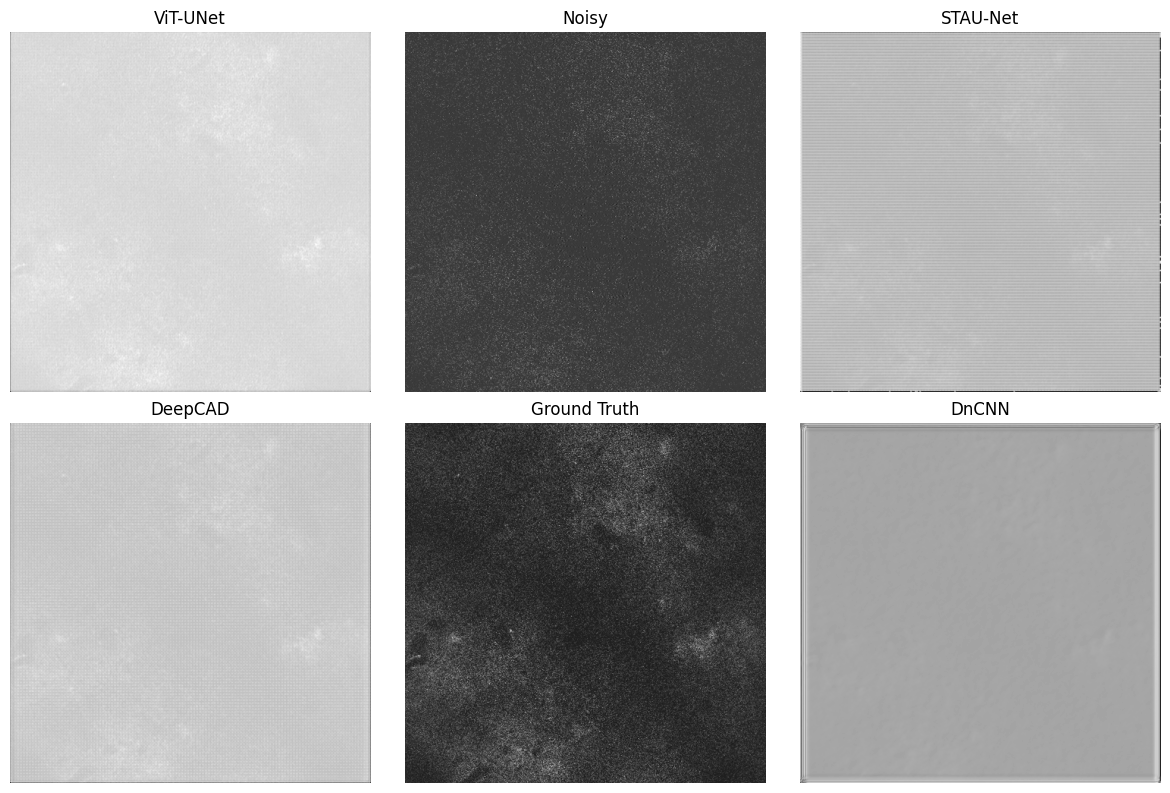

DONE


In [16]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

import os
import numpy as np
import torch
import torch.nn.functional as F
import tifffile
import matplotlib.pyplot as plt
import gc

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11
INPUT_CHANNELS = 10

VAL_DIR = "/kaggle/input/validationmouse"
WEIGHTS_DIR = "/kaggle/input/trainedmodels"

LOW_FILE  = "1_ATP2D_476x476x7100_lowSNR.tif"
HIGH_FILE = "1_ATP2D_476x476x7100_highSNR.tif"

# ==========================
# LOAD DATA
# ==========================
noisy = tifffile.imread(os.path.join(VAL_DIR, LOW_FILE)).astype(np.float32)
gt    = tifffile.imread(os.path.join(VAL_DIR, HIGH_FILE)).astype(np.float32)

# Fix axis order
if noisy.shape[0] == 476 and noisy.shape[2] == 7100:
    noisy = np.transpose(noisy,(2,0,1))
    gt    = np.transpose(gt,(2,0,1))

FRAMES,H,W = noisy.shape

center = FRAMES // 2
half = TEMPORAL_WINDOW // 2

context = noisy[center-half:center+half+1]

context = np.concatenate(
    (context[:half], context[half+1:]),
    axis=0
)

context2d = torch.from_numpy(context).unsqueeze(0).float().to(DEVICE)
context3d = torch.from_numpy(context).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
# ==========================
# MODEL LIST
# ==========================

model_configs = [

("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), "ViT_UNet_best.pth", "2D"),
("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), "STAU_Net_best.pth", "2D"),
("DeepCAD", DeepCAD_3D_UNet(in_channels=1), "DeepCAD_best.pth", "3D"),
("DnCNN", DnCNN(channels=INPUT_CHANNELS), "DnCNN_best.pth", "2D")

]

results = {}

# ==========================
# RUN MODELS
# ==========================

for name, model, weight, mode in model_configs:

    print("Running", name)

    state = torch.load(os.path.join(WEIGHTS_DIR, weight), map_location=DEVICE)

    clean = {k.replace("module.",""):v for k,v in state.items()}

    model.load_state_dict(clean)
    model.to(DEVICE)
    model.eval()

    with torch.no_grad():

        if mode == "3D":
            out = model(context3d)
            out = out.mean(dim=2)
        else:
            out = model(context2d)

    results[name] = out.squeeze().cpu().numpy()

    del model
    torch.cuda.empty_cache()
    gc.collect()

# ==========================
# SHOW GRID
# ==========================

plt.figure(figsize=(12,8))

names = list(results.keys())

plt.subplot(2,3,1)
plt.imshow(results[names[0]], cmap="gray")
plt.title(names[0])
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(noisy[center], cmap="gray")
plt.title("Noisy")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(results[names[1]], cmap="gray")
plt.title(names[1])
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(results[names[2]], cmap="gray")
plt.title(names[2])
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(gt[center], cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(2,3,6)
plt.imshow(results[names[3]], cmap="gray")
plt.title(names[3])
plt.axis("off")

plt.tight_layout()
plt.savefig("MODEL_COMPARISON_FIXED.png", dpi=300)
plt.show()

print("DONE")


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

# =========================================================================
# 2. METRIC CALCULATION
# =========================================================================
def evaluate_model_on_file(model, noisy_file, gt_file, mode='2.5D', batch_size=32):
    ds = PairedValidationDataset(noisy_file, gt_file, mode=mode)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    
    model.eval()
    total_psnr = 0
    total_ssim = 0
    count = 0
    
    # Warmup
    try:
        dummy = next(iter(loader))[0].to(DEVICE)
        with torch.no_grad(): _ = model(dummy)
    except StopIteration: return 0, 0, 0

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)
    total_inference_time_ms = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            
            start_event.record()
            outputs = model(inputs)
            end_event.record()
            torch.cuda.synchronize()
            
            total_inference_time_ms += start_event.elapsed_time(end_event)
            
            # --- Handle Output Shapes ---
            if mode == '3D':
                # DeepCAD output (B, 1, 10, H, W) -> Collapse to (B, 1, H, W)
                outputs = outputs.mean(dim=2)
            
            out_np = outputs.cpu().numpy().squeeze()
            tgt_np = targets.cpu().numpy().squeeze()
            
            if len(out_np.shape) == 2:
                out_np = out_np[None, ...]
                tgt_np = tgt_np[None, ...]
            
            for b in range(out_np.shape[0]):
                p = psnr(tgt_np[b], out_np[b], data_range=1.0)
                s = ssim(tgt_np[b], out_np[b], data_range=1.0)
                total_psnr += p
                total_ssim += s
                count += 1
                
    if count == 0: return 0, 0, 0
    
    return total_psnr / count, total_ssim / count, total_inference_time_ms / 1000.0

# =========================================================================
# 3. MAIN EVALUATION LOOP
# =========================================================================
VAL_DIR = "/kaggle/input/dataset/dataset1/Validation"
gt_path = os.path.join(VAL_DIR, "F0.tif")
files_to_test = ["F1.tif","F2.tif","F3.tif"]
WEIGHTS_DIR = "/kaggle/input/trainedmodels"





# NOTE: We initialize models with INPUT_CHANNELS (10), not TEMPORAL_WINDOW (11)
model_configs = [
    ("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "ViT_UNet_best.pth")),
    ("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "STAU_Net_best.pth")),
    ("DeepCAD", DeepCAD_3D_UNet(in_channels=1), '3D', os.path.join(WEIGHTS_DIR, "DeepCAD_best.pth")),
    ("DnCNN", DnCNN(channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "DnCNN_best.pth"))
]

results_data = []

print("\n=== STARTING EVALUATION SUITE ===")

for model_name, model_inst, mode, weight_path in model_configs:
    print(f"\nLoading {model_name}...")
    try:

        
        state_dict = torch.load(weight_path, map_location=DEVICE)

        # Remove "module." prefix if present
        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("module."):
                new_state_dict[k[7:]] = v
            else:
                new_state_dict[k] = v
        
        model_inst.load_state_dict(new_state_dict)
        
        model_inst.to(DEVICE)
        
        for fname in files_to_test:
            noisy_path = os.path.join(VAL_DIR, fname)
            if not os.path.exists(noisy_path): continue
            
            p, s, t = evaluate_model_on_file(model_inst, noisy_path, gt_path, mode=mode)
            print(f"  -> {fname}: PSNR={p:.2f} | SSIM={s:.4f} | Time={t:.4f}s")
            results_data.append([model_name, fname, round(p, 4), round(s, 4), round(t, 4)])
        
        del model_inst
        torch.cuda.empty_cache()
        
    except Exception as e:
        print(f"Error loading/running {model_name}: {e}")
1
# Save CSV
csv_filename = "validation_results.csv"
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Model", "File", "PSNR (dB)", "SSIM", "Runtime (s)"])
    writer.writerows(results_data)

print(f"\n>>> Done. Results saved to {csv_filename}")

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import tifffile
from tqdm import tqdm
import torch.cuda.amp as amp
import gc

import time
import csv
import torch
import tifffile
import numpy as np
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# =========================================================================
# CONFIGURATION
# =========================================================================

DEVICE = torch.device("cuda")
torch.backends.cudnn.benchmark = True

print("Using GPU:", torch.cuda.get_device_name(0))

TEMPORAL_WINDOW = 11 
INPUT_CHANNELS = TEMPORAL_WINDOW - 1  # 10 Frames (Must match training)

# =========================================================================
# 1. PAIRED DATASET (With Blind Spot Logic)
# =========================================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck
        self.conv_to_token = nn.Conv2d(base*2, 256, 1) 
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base*4, 1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b_out = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))
        d1 = self.up1(b_out)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 3. STAU-Net
# =========================================================================
class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        
    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(in_channels, base, 3, 1, 1), nn.ReLU(), nn.Conv2d(base, base, 3, 1, 1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base*2, 3, 1, 1), nn.ReLU(), nn.Conv2d(base*2, base*2, 3, 1, 1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        
        # Bottleneck: LSTM
        self.lstm_in_dim = base*2
        self.lstm = nn.LSTM(self.lstm_in_dim, self.lstm_in_dim, batch_first=True, bidirectional=False)
        
        # Decoder
        self.up1 = nn.ConvTranspose2d(base*2, base*2, 2, 2)
        self.att1 = AttentionGate(F_g=base*2, F_l=base*2, F_int=base)
        self.dec1 = nn.Sequential(nn.Conv2d(base*4, base*2, 3, 1, 1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.att2 = AttentionGate(F_g=base, F_l=base, F_int=base//2)
        self.dec2 = nn.Sequential(nn.Conv2d(base*2, base, 3, 1, 1), nn.ReLU())
        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.pool2(e2)
        B, C, H, W = b.shape
        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C) 
        lstm_out, _ = self.lstm(b_flat)
        b_out = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
        d1 = self.up1(b_out)
        e2_gated = self.att1(g=d1, x=e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))
        d2 = self.up2(d1)
        e1_gated = self.att2(g=d2, x=e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))
        return self.final(d2)

# =========================================================================
# 4. DeepCAD (3D)
# =========================================================================
class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16): 
        super().__init__()
        def conv_block_3d(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c), nn.ReLU(inplace=True)
            )
        self.enc1 = conv_block_3d(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = conv_block_3d(base, base*2)
        self.pool2 = nn.MaxPool3d(2)
        self.bottleneck = conv_block_3d(base*2, base*4)
        self.up1 = nn.ConvTranspose3d(base*4, base*2, 2, stride=2)
        self.dec1 = conv_block_3d(base*4, base*2)
        self.up2 = nn.ConvTranspose3d(base*2, base, 2, stride=2)
        self.dec2 = conv_block_3d(base*2, base)
        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        # x: (B, 1, 10, H, W)
        e1 = self.enc1(x)
        p1 = self.pool1(e1)
        e2 = self.enc2(p1)
        p2 = self.pool2(e2)
        b = self.bottleneck(p2)
        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]: d1 = F.interpolate(d1, size=e2.shape[2:])
        d1 = self.dec1(torch.cat([d1, e2], dim=1))
        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]: d2 = F.interpolate(d2, size=e1.shape[2:])
        d2 = self.dec2(torch.cat([d2, e1], dim=1))
        return self.final(d2)

# =========================================================================
# 5. DnCNN (MODIFIED FOR INTERPOLATION)
# =========================================================================
class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super(DnCNN, self).__init__()
        kernel_size = 3
        padding = 1
        features = 64
        layers = []
        # Input channels is 10 (context frames)
        layers.append(nn.Conv2d(channels, features, kernel_size=kernel_size, padding=padding, bias=False))
        layers.append(nn.ReLU(inplace=True))
        for _ in range(num_of_layers - 2):
            layers.append(nn.Conv2d(features, features, kernel_size=kernel_size, padding=padding, bias=False))
            layers.append(nn.BatchNorm2d(features))
            layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(features, 1, kernel_size=kernel_size, padding=padding, bias=False))
        self.dncnn = nn.Sequential(*layers)
        
    def forward(self, x):
        # Direct Prediction of the missing center frame
        # NO residual subtraction (x - noise) because x doesn't contain the center frame
        out = self.dncnn(x)
        return out


class PairedValidationDataset(Dataset):
    def __init__(self, noisy_path, gt_path, patch_size=64, mode='2.5D'):
        self.mode = mode
        self.patch_size = patch_size
        self.window = TEMPORAL_WINDOW
        self.half = self.window // 2
        
        print(f"Loading pair: {os.path.basename(noisy_path)}")
        '''
        self.noisy = tifffile.imread(noisy_path).astype(np.float32)
        self.gt = tifffile.imread(gt_path).astype(np.float32)
        '''
        with tifffile.TiffFile(noisy_path) as tif:
            self.noisy = tif.asarray(out='memmap')
        
        with tifffile.TiffFile(gt_path) as tif:
            self.gt = tif.asarray(out='memmap')
        
        self.noisy = self.noisy.astype(np.float32)
        self.gt = self.gt.astype(np.float32)
        
        # Normalize
        self.noisy = self.noisy / (self.noisy.max() + 1e-8)
        self.gt = self.gt / (self.gt.max() + 1e-8)
        
        self.F, self.H, self.W = self.noisy.shape
        
        self.coords = []
        stride = 64 
        start_t = self.half
        end_t = self.F - self.half
        
        for t in range(start_t, end_t, 2): 
            for y in range(0, self.H - patch_size + 1, stride):
                for x in range(0, self.W - patch_size + 1, stride):
                    self.coords.append((t, y, x))
                    
    def __len__(self):
        return len(self.coords)

    def __getitem__(self, idx):
        t, y, x = self.coords[idx]
        
        # Get Full Window
        full_window = self.noisy[t-self.half : t+self.half+1, y:y+self.patch_size, x:x+self.patch_size]
        
        # Get Target (Clean GT center frame)
        tgt_slice = self.gt[t, y:y+self.patch_size, x:x+self.patch_size]
        
        # --- BLIND SPOT LOGIC (Must Match Training) ---
        # Remove the center frame from input
        inp_slice = np.concatenate((full_window[:self.half], full_window[self.half+1:]), axis=0)
        
        if self.mode == '3D':
            # Input: (1, 10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).unsqueeze(0).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor
        else:
            # Input: (10, H, W)
            inp_tensor = torch.from_numpy(inp_slice).float()
            tgt_tensor = torch.from_numpy(tgt_slice).unsqueeze(0).float()
            return inp_tensor, tgt_tensor

# =========================================================================
# 2. METRIC CALCULATION
# =========================================================================
def evaluate_model_on_file(model, noisy_file, gt_file, mode='2.5D', batch_size=32):
    ds = PairedValidationDataset(noisy_file, gt_file, mode=mode)
    loader = DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True
    )    
    model.eval()
    total_psnr = 0
    total_ssim = 0
    count = 0
    
    # Warmup
    try:
        dummy = next(iter(loader))[0].to(DEVICE)
        with torch.no_grad(): _ = model(dummy)
    except StopIteration: return 0, 0, 0

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)
    total_inference_time_ms = 0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            
            start_event.record()
            outputs = model(inputs)
            end_event.record()
            torch.cuda.synchronize()
            
            total_inference_time_ms += start_event.elapsed_time(end_event)
            
            # --- Handle Output Shapes ---
            if mode == '3D':
                # DeepCAD output (B, 1, 10, H, W) -> Collapse to (B, 1, H, W)
                outputs = outputs.mean(dim=2)
            
            out_np = outputs.cpu().numpy().squeeze()
            tgt_np = targets.cpu().numpy().squeeze()
            
            if len(out_np.shape) == 2:
                out_np = out_np[None, ...]
                tgt_np = tgt_np[None, ...]
            
            for b in range(out_np.shape[0]):
                p = psnr(tgt_np[b], out_np[b], data_range=1.0)
                s = ssim(tgt_np[b], out_np[b], data_range=1.0)
                total_psnr += p
                total_ssim += s
                count += 1
                
    if count == 0: return 0, 0, 0
    
    return total_psnr / count, total_ssim / count, total_inference_time_ms / 1000.0

# =========================================================================
# 3. MAIN EVALUATION LOOP
# =========================================================================
VAL_DIR = "/kaggle/input/dataset/dataset1/Validation"
gt_path = os.path.join(VAL_DIR, "F0.tif")
files_to_test = ["F1.tif","F2.tif","F3.tif"]
WEIGHTS_DIR = "/kaggle/input/trainedmodels"



# NOTE: We initialize models with INPUT_CHANNELS (10), not TEMPORAL_WINDOW (11)
model_configs = [
    ("ViT-UNet", ViT_UNet(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "ViT_UNet_best.pth")),
    ("STAU-Net", STAU_Net(in_channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "STAU_Net_best.pth")),
    ("DeepCAD", DeepCAD_3D_UNet(in_channels=1), '3D', os.path.join(WEIGHTS_DIR, "DeepCAD_best.pth")),
    ("DnCNN", DnCNN(channels=INPUT_CHANNELS), '2.5D', os.path.join(WEIGHTS_DIR, "DnCNN_best.pth"))
]

results_data = []

print("\n=== STARTING EVALUATION SUITE ===")

for model_name, model_inst, mode, weight_path in model_configs:
    print(f"\nLoading {model_name}...")
    try:

        
        state_dict = torch.load(weight_path, map_location=DEVICE)

        # Remove "module." prefix if present
        new_state_dict = {}
        for k, v in state_dict.items():
            if k.startswith("module."):
                new_state_dict[k[7:]] = v
            else:
                new_state_dict[k] = v
        
        model_inst.load_state_dict(new_state_dict)
        
        model_inst.to(DEVICE)
        
        for fname in files_to_test:
            noisy_path = os.path.join(VAL_DIR, fname)
            if not os.path.exists(noisy_path): continue
            
            p, s, t = evaluate_model_on_file(model_inst, noisy_path, gt_path, mode=mode)
            print(f"  -> {fname}: PSNR={p:.2f} | SSIM={s:.4f} | Time={t:.4f}s")
            results_data.append([model_name, fname, round(p, 4), round(s, 4), round(t, 4)])
        
        del model_inst
        torch.cuda.empty_cache()
        
    except Exception as e:
        print(f"Error loading/running {model_name}: {e}")
1
# Save CSV
csv_filename = "validation_results.csv"
with open(csv_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Model", "File", "PSNR (dB)", "SSIM", "Runtime (s)"])
    writer.writerows(results_data)

print(f"\n>>> Done. Results saved to {csv_filename}")

Using GPU: Tesla T4

=== STARTING EVALUATION SUITE ===

Loading ViT-UNet...
Loading pair: F1.tif
  -> F1.tif: PSNR=57.59 | SSIM=0.9968 | Time=48.1536s
Loading pair: F2.tif
  -> F2.tif: PSNR=50.32 | SSIM=0.9789 | Time=50.5272s
Loading pair: F3.tif
  -> F3.tif: PSNR=46.30 | SSIM=0.9401 | Time=53.5413s

Loading STAU-Net...
Loading pair: F1.tif
  -> F1.tif: PSNR=56.25 | SSIM=0.9955 | Time=12.9217s
Loading pair: F2.tif
  -> F2.tif: PSNR=50.18 | SSIM=0.9784 | Time=12.8483s
Loading pair: F3.tif
  -> F3.tif: PSNR=46.58 | SSIM=0.9454 | Time=12.8409s

Loading DeepCAD...
Loading pair: F1.tif
  -> F1.tif: PSNR=56.69 | SSIM=0.9960 | Time=87.4112s
Loading pair: F2.tif
  -> F2.tif: PSNR=50.05 | SSIM=0.9775 | Time=85.3468s
Loading pair: F3.tif
  -> F3.tif: PSNR=45.11 | SSIM=0.9125 | Time=85.3670s

Loading DnCNN...
Loading pair: F1.tif
  -> F1.tif: PSNR=54.32 | SSIM=0.9923 | Time=39.9916s
Loading pair: F2.tif
  -> F2.tif: PSNR=49.20 | SSIM=0.9716 | Time=39.9643s
Loading pair: F3.tif
  -> F3.tif: PSNR=4

In [2]:
"""
Create an improved qualitative Figure 3 for denoising comparisons.

The figure layout is:
    Row 1: Full-frame views with the same zoom ROI boxed.
    Row 2: Zoomed crops from that ROI.
    Row 3: Absolute difference maps against ground truth.

Notebook use, after you already have `noisy`, `gt`, and `results`:

    from figure3_qualitative_improved import make_figure3

    make_figure3(
        noisy=noisy,
        ground_truth=gt,
        predictions={
            "DnCNN": results["DnCNN"],
            "DeepCAD": results["DeepCAD"],
            "ViT-UNet": results["ViT-UNet"],
            "STAU-Net": results["STAU-Net"],
        },
        frame=center,
        crop_size=96,
        out_path="Figure3_qualitative_improved.png",
    )

CLI use with TIFF/PNG/JPG inputs:

    python figure3_qualitative_improved.py \
        --noisy noisy.tif \
        --gt ground_truth.tif \
        --dncnn dncnn.tif \
        --deepcad deepcad.tif \
        --vit vit_unet.tif \
        --stau stau_net.tif \
        --frame middle \
        --crop-size 96
"""

from __future__ import annotations

import argparse
import os
from pathlib import Path
from typing import Dict, Mapping, Optional, Sequence, Tuple, Union

import numpy as np

try:
    import tifffile
except ImportError:  # pragma: no cover - only needed for CLI TIFF loading
    tifffile = None


ArrayLike = Union[np.ndarray, Sequence[float]]
Roi = Tuple[int, int, int, int]  # x, y, width, height


DEFAULT_CAPTION = (
    "Figure 3. Qualitative denoising comparison on a representative validation "
    "frame. The boxed region in the full-frame images is enlarged in the second "
    "row to expose fine structures that are difficult to compare at full scale. "
    "Zoomed views show that STAU-Net suppresses granular noise while preserving "
    "calcium-event boundaries and local morphology. The bottom row shows "
    "absolute error maps against the high-SNR ground truth, where darker regions "
    "indicate lower residual error; STAU-Net produces a cleaner residual pattern "
    "in the highlighted region than the baseline denoisers."
)


def _get_matplotlib():
    os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
    os.environ.setdefault("XDG_CACHE_HOME", "/tmp")
    import matplotlib

    matplotlib.use("Agg", force=True)
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    return plt, Rectangle


def _as_float_image(image: ArrayLike) -> np.ndarray:
    arr = np.asarray(image)
    arr = np.squeeze(arr)
    if arr.ndim not in (2, 3):
        raise ValueError(f"Expected a 2D image or 3D stack, got shape {arr.shape}.")
    return arr.astype(np.float32, copy=False)


def _select_frame(image: ArrayLike, frame: Optional[Union[int, str]]) -> np.ndarray:
    arr = _as_float_image(image)
    if arr.ndim == 2:
        return arr

    if frame is None or frame == "middle":
        idx = arr.shape[0] // 2
    else:
        idx = int(frame)
        if idx < 0:
            idx = arr.shape[0] + idx
    if idx < 0 or idx >= arr.shape[0]:
        raise IndexError(f"Frame {idx} is outside stack with {arr.shape[0]} frames.")
    return arr[idx]


def _normalize_images(images: Mapping[str, np.ndarray]) -> Dict[str, np.ndarray]:
    finite_pixels = []
    for image in images.values():
        values = image[np.isfinite(image)]
        if values.size:
            finite_pixels.append(values.ravel())
    if not finite_pixels:
        raise ValueError("No finite pixels found in the provided images.")

    sample = np.concatenate(finite_pixels)
    lo, hi = np.percentile(sample, [0.5, 99.7])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        lo, hi = float(np.min(sample)), float(np.max(sample))
    if hi <= lo:
        hi = lo + 1.0

    normalized = {}
    for name, image in images.items():
        img = np.nan_to_num(image, nan=lo, posinf=hi, neginf=lo)
        normalized[name] = np.clip((img - lo) / (hi - lo), 0.0, 1.0)
    return normalized


def _candidate_roi_score(
    noisy: np.ndarray,
    ground_truth: np.ndarray,
    x: int,
    y: int,
    crop_size: int,
) -> float:
    noisy_crop = noisy[y : y + crop_size, x : x + crop_size]
    gt_crop = ground_truth[y : y + crop_size, x : x + crop_size]
    residual = np.mean(np.abs(noisy_crop - gt_crop))
    structure = np.std(gt_crop)
    return float(residual + 0.35 * structure)


def choose_roi(
    noisy: ArrayLike,
    ground_truth: ArrayLike,
    crop_size: int = 96,
    stride: Optional[int] = None,
) -> Roi:
    """Pick a region where noise and underlying structure are both visible."""
    noisy_2d = _as_float_image(noisy)
    gt_2d = _as_float_image(ground_truth)
    if noisy_2d.shape != gt_2d.shape:
        raise ValueError(f"Noisy and ground-truth shapes differ: {noisy_2d.shape} vs {gt_2d.shape}.")

    h, w = gt_2d.shape
    crop_size = int(min(crop_size, h, w))
    stride = int(stride or max(8, crop_size // 3))

    best_score = -np.inf
    best_xy = ((w - crop_size) // 2, (h - crop_size) // 2)

    for y in range(0, h - crop_size + 1, stride):
        for x in range(0, w - crop_size + 1, stride):
            score = _candidate_roi_score(noisy_2d, gt_2d, x, y, crop_size)
            if score > best_score:
                best_score = score
                best_xy = (x, y)

    return best_xy[0], best_xy[1], crop_size, crop_size


def _crop(image: np.ndarray, roi: Roi) -> np.ndarray:
    x, y, width, height = roi
    return image[y : y + height, x : x + width]


def _load_image(path: Union[str, Path]) -> np.ndarray:
    path = Path(path)
    if path.suffix.lower() in {".tif", ".tiff"}:
        if tifffile is None:
            raise ImportError("Install tifffile to load TIFF stacks.")
        return tifffile.imread(path)
    plt, _ = _get_matplotlib()
    return plt.imread(path)


def make_figure3(
    noisy: ArrayLike,
    ground_truth: ArrayLike,
    predictions: Mapping[str, ArrayLike],
    frame: Optional[Union[int, str]] = "middle",
    roi: Optional[Roi] = None,
    crop_size: int = 96,
    out_path: Union[str, Path] = "Figure3_qualitative_improved.png",
    caption_path: Optional[Union[str, Path]] = "Figure3_caption.txt",
    dpi: int = 300,
) -> Roi:
    """
    Generate Figure 3 and return the ROI as (x, y, width, height).

    Use `roi=(x, y, w, h)` when you want to force the exact crop shown in the
    paper. Leave it as None to automatically choose a high-signal, high-noise
    region from the noisy/GT pair.
    """
    ordered_names = ["Noisy", "DnCNN", "DeepCAD", "ViT-UNet", "STAU-Net", "Ground Truth"]
    images_raw: Dict[str, np.ndarray] = {
        "Noisy": _select_frame(noisy, frame),
        "Ground Truth": _select_frame(ground_truth, frame),
    }
    for name in ["DnCNN", "DeepCAD", "ViT-UNet", "STAU-Net"]:
        if name not in predictions:
            raise KeyError(f"Missing prediction for {name}. Available keys: {list(predictions)}")
        images_raw[name] = _select_frame(predictions[name], frame)

    shape = images_raw["Ground Truth"].shape
    for name, image in images_raw.items():
        if image.shape != shape:
            raise ValueError(f"{name} has shape {image.shape}, expected {shape}.")

    images = _normalize_images({name: images_raw[name] for name in ordered_names})
    if roi is None:
        roi = choose_roi(images["Noisy"], images["Ground Truth"], crop_size=crop_size)

    diffs = {name: np.abs(images[name] - images["Ground Truth"]) for name in ordered_names}
    diff_crops = {name: _crop(diffs[name], roi) for name in ordered_names}
    diff_values = np.concatenate([diff_crops[name].ravel() for name in ordered_names if name != "Ground Truth"])
    diff_vmax = float(np.percentile(diff_values, 99.0))
    if diff_vmax <= 0 or not np.isfinite(diff_vmax):
        diff_vmax = 1.0

    plt, Rectangle = _get_matplotlib()

    fig, axes = plt.subplots(
        3,
        len(ordered_names),
        figsize=(18, 8.5),
        gridspec_kw={"height_ratios": [1.0, 1.0, 1.0]},
        constrained_layout=True,
    )

    for col, name in enumerate(ordered_names):
        full_ax = axes[0, col]
        zoom_ax = axes[1, col]
        diff_ax = axes[2, col]

        full_ax.imshow(images[name], cmap="gray", vmin=0, vmax=1)
        full_ax.set_title(name, fontsize=12, fontweight="bold")
        box_color = "red" if name == "Noisy" else "lime"
        x, y, width, height = roi
        full_ax.add_patch(
            Rectangle((x, y), width, height, fill=False, edgecolor=box_color, linewidth=2.2)
        )
        full_ax.axis("off")

        zoom_ax.imshow(_crop(images[name], roi), cmap="gray", vmin=0, vmax=1)
        zoom_ax.set_title("Zoomed ROI", fontsize=10)
        zoom_ax.axis("off")

        diff = diff_crops[name]
        diff_ax.imshow(diff, cmap="inferno", vmin=0, vmax=diff_vmax)
        mae = float(np.mean(diff))
        diff_ax.set_title(f"ROI |Error| vs GT\nMAE={mae:.4f}", fontsize=10)
        diff_ax.axis("off")

    axes[0, 0].set_ylabel("Full frame", fontsize=12, fontweight="bold")
    axes[1, 0].set_ylabel("Zoom crop", fontsize=12, fontweight="bold")
    axes[2, 0].set_ylabel("Difference map", fontsize=12, fontweight="bold")

    fig.suptitle(
        "Qualitative Denoising Comparison with Zoomed ROI and Ground-Truth Error Maps",
        fontsize=15,
        fontweight="bold",
    )

    out_path = Path(out_path)
    fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
    fig.savefig(out_path.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)

    if caption_path is not None:
        Path(caption_path).write_text(DEFAULT_CAPTION + "\n", encoding="utf-8")

    return roi


def _parse_frame(value: str) -> Union[int, str]:
    if value == "middle":
        return value
    return int(value)


def main() -> None:
    parser = argparse.ArgumentParser(description="Generate improved Figure 3 qualitative comparison.")
    parser.add_argument("--noisy", required=True, help="Path to noisy low-SNR image/stack.")
    parser.add_argument("--gt", required=True, help="Path to high-SNR ground-truth image/stack.")
    parser.add_argument("--dncnn", required=True, help="Path to DnCNN output image/stack.")
    parser.add_argument("--deepcad", required=True, help="Path to DeepCAD output image/stack.")
    parser.add_argument("--vit", required=True, help="Path to ViT-UNet output image/stack.")
    parser.add_argument("--stau", required=True, help="Path to STAU-Net output image/stack.")
    parser.add_argument("--frame", default="middle", type=_parse_frame, help="'middle' or a zero-based frame index.")
    parser.add_argument("--crop-size", default=96, type=int, help="Zoom crop width/height in pixels.")
    parser.add_argument("--roi", nargs=4, type=int, metavar=("X", "Y", "W", "H"), help="Manual ROI.")
    parser.add_argument("--out", default="Figure3_qualitative_improved.png", help="Output PNG path.")
    parser.add_argument("--caption", default="Figure3_caption.txt", help="Output caption text path.")
    args = parser.parse_args()

    roi = make_figure3(
        noisy=_load_image(args.noisy),
        ground_truth=_load_image(args.gt),
        predictions={
            "DnCNN": _load_image(args.dncnn),
            "DeepCAD": _load_image(args.deepcad),
            "ViT-UNet": _load_image(args.vit),
            "STAU-Net": _load_image(args.stau),
        },
        frame=args.frame,
        roi=tuple(args.roi) if args.roi else None,
        crop_size=args.crop_size,
        out_path=args.out,
        caption_path=args.caption,
    )
    print(f"Saved improved Figure 3 to {args.out}")
    print(f"Saved PDF version to {Path(args.out).with_suffix('.pdf')}")
    print(f"Saved caption to {args.caption}")
    print(f"ROI used: x={roi[0]}, y={roi[1]}, width={roi[2]}, height={roi[3]}")


if __name__ == "__main__":
    main()


usage: colab_kernel_launcher.py [-h] --noisy NOISY --gt GT --dncnn DNCNN
                                --deepcad DEEPCAD --vit VIT --stau STAU
                                [--frame FRAME] [--crop-size CROP_SIZE]
                                [--roi X Y W H] [--out OUT]
                                [--caption CAPTION]
colab_kernel_launcher.py: error: the following arguments are required: --noisy, --gt, --dncnn, --deepcad, --vit, --stau


SystemExit: 2

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ----------------------------
# CONFIG
# ----------------------------
frame_idx = noisy.shape[0] // 2   # change if needed
crop_size = 96                    # try 64, 96, or 128
save_path = "Figure3_qualitative_improved.png"

# Expected:
# noisy: low-SNR stack, shape (T, H, W)
# gt: ground-truth stack, shape (T, H, W)
# results: dictionary with denoised outputs
# results["DnCNN"], results["DeepCAD"], results["ViT-UNet"], results["STAU-Net"]

images = {
    "Noisy": noisy[frame_idx],
    "DnCNN": results["DnCNN"],
    "DeepCAD": results["DeepCAD"],
    "ViT-UNet": results["ViT-UNet"],
    "STAU-Net": results["STAU-Net"],
    "Ground Truth": gt[frame_idx],
}

# If model outputs are stacks, select same frame
for k in images:
    if images[k].ndim == 3:
        images[k] = images[k][frame_idx]

# ----------------------------
# NORMALIZE CONSISTENTLY
# ----------------------------
all_pixels = np.concatenate([img.ravel() for img in images.values()])
vmin, vmax = np.percentile(all_pixels, [0.5, 99.7])

for k in images:
    images[k] = np.clip((images[k] - vmin) / (vmax - vmin + 1e-8), 0, 1)

# ----------------------------
# AUTO-PICK ROI
# ----------------------------
def choose_roi(noisy_img, gt_img, crop_size=96, stride=32):
    H, W = noisy_img.shape
    best_score = -1
    best_xy = (W // 2 - crop_size // 2, H // 2 - crop_size // 2)

    for y in range(0, H - crop_size + 1, stride):
        for x in range(0, W - crop_size + 1, stride):
            noisy_crop = noisy_img[y:y+crop_size, x:x+crop_size]
            gt_crop = gt_img[y:y+crop_size, x:x+crop_size]

            noise_score = np.mean(np.abs(noisy_crop - gt_crop))
            structure_score = np.std(gt_crop)
            score = noise_score + 0.35 * structure_score

            if score > best_score:
                best_score = score
                best_xy = (x, y)

    return best_xy[0], best_xy[1], crop_size, crop_size

x, y, w, h = choose_roi(
    images["Noisy"],
    images["Ground Truth"],
    crop_size=crop_size,
    stride=max(16, crop_size // 3)
)

def crop(img):
    return img[y:y+h, x:x+w]

# ----------------------------
# DIFFERENCE MAPS
# ----------------------------
diff_maps = {}

for name, img in images.items():
    diff_maps[name] = np.abs(img - images["Ground Truth"])

diff_values = np.concatenate([
    crop(diff_maps[name]).ravel()
    for name in images
    if name != "Ground Truth"
])

diff_vmax = np.percentile(diff_values, 99)

# ----------------------------
# PLOT FIGURE 3
# ----------------------------
names = ["Noisy", "DnCNN", "DeepCAD", "ViT-UNet", "STAU-Net", "Ground Truth"]

fig, axes = plt.subplots(
    3,
    len(names),
    figsize=(18, 8.5),
    gridspec_kw={"height_ratios": [1, 1, 1]},
    constrained_layout=True
)

for col, name in enumerate(names):
    img = images[name]

    # Row 1: full images
    axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(name, fontsize=12, fontweight="bold")

    box_color = "red" if name == "Noisy" else "lime"
    rect = Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        edgecolor=box_color,
        linewidth=2.2
    )
    axes[0, col].add_patch(rect)
    axes[0, col].axis("off")

    # Row 2: zoom crops
    axes[1, col].imshow(crop(img), cmap="gray", vmin=0, vmax=1)
    axes[1, col].axis("off")

    # Row 3: difference maps
    diff_crop = crop(diff_maps[name])
    mae = np.mean(diff_crop)

    axes[2, col].imshow(diff_crop, cmap="inferno", vmin=0, vmax=diff_vmax)
    axes[2, col].set_title(f"MAE={mae:.4f}", fontsize=10)
    axes[2, col].axis("off")

axes[0, 0].set_ylabel("Full Image", fontsize=12, fontweight="bold")
axes[1, 0].set_ylabel("Zoomed ROI", fontsize=12, fontweight="bold")
axes[2, 0].set_ylabel("Error Map", fontsize=12, fontweight="bold")

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.savefig(save_path.replace(".png", ".pdf"), bbox_inches="tight")
plt.show()

print("Saved:", save_path)
print("ROI:", x, y, w, h)


NameError: name 'noisy' is not defined

Using device: cuda
GT shape: (1500, 490, 490)
Noisy shape: (1500, 490, 490)
Selected frame: 750
Loading: /kaggle/input/trainedmodels/DnCNN_best.pth
Loading: /kaggle/input/trainedmodels/DeepCAD_best.pth
Loading: /kaggle/input/trainedmodels/ViT_UNet_best.pth
Loading: /kaggle/input/trainedmodels/STAU_Net_best.pth

Running DnCNN



Running DeepCAD



Running ViT-UNet



Running STAU-Net


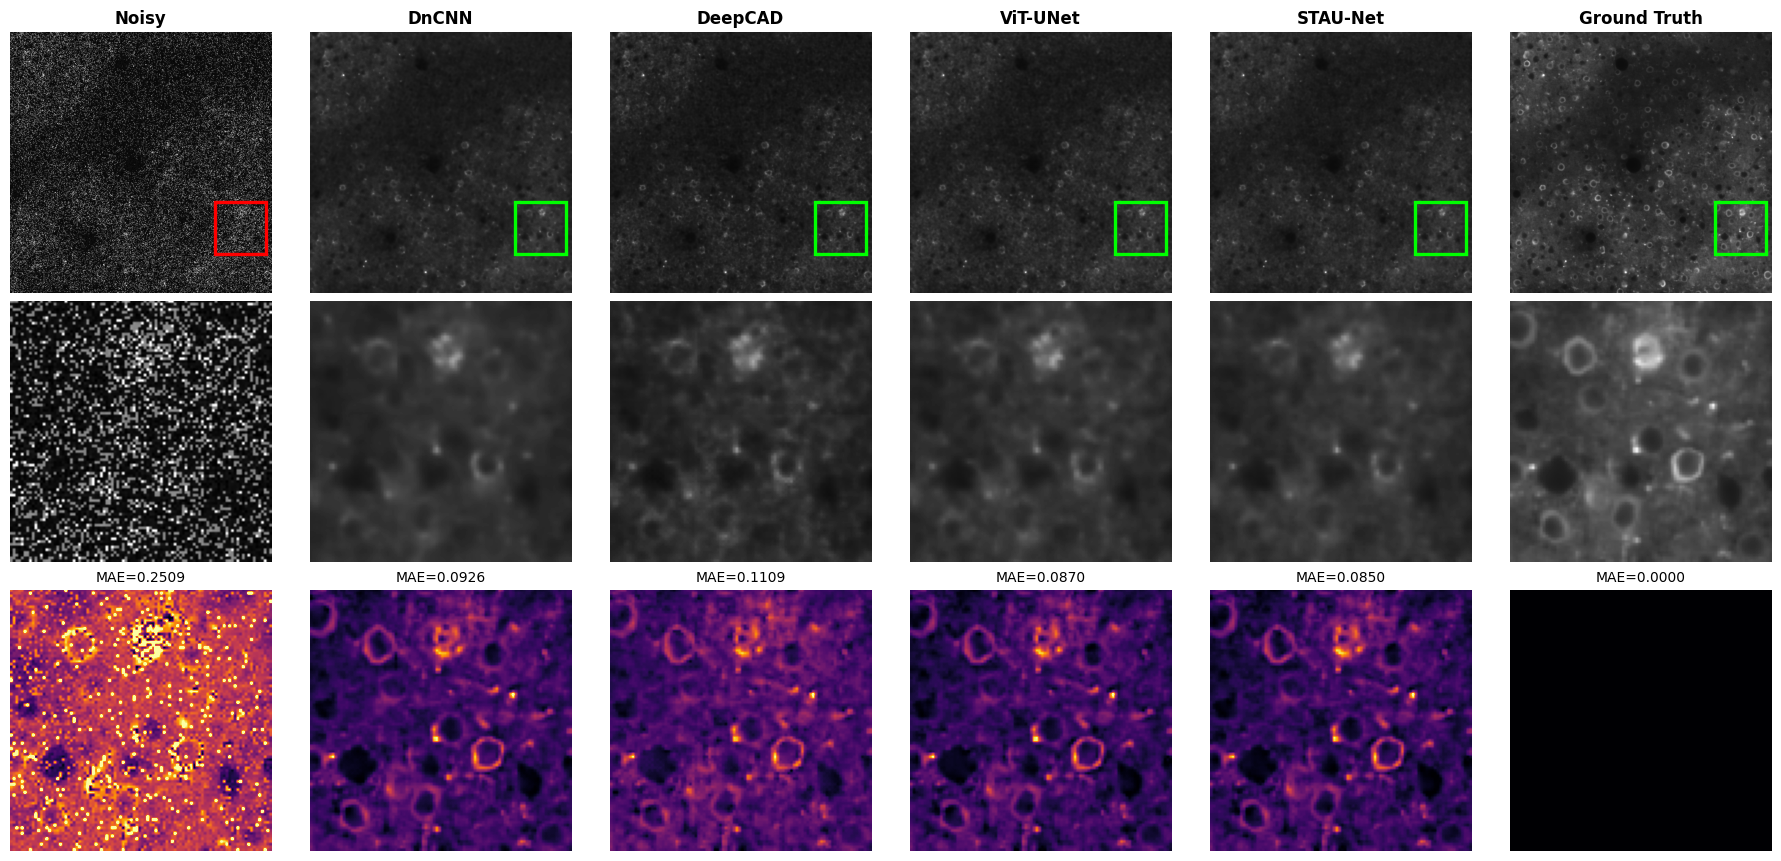

Saved: Figure3_qualitative_improved.png
Saved: Figure3_qualitative_improved.pdf
ROI used: 384 320 96 96


In [4]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import tifffile
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from tqdm import tqdm

# ============================================================
# PATHS
# ============================================================

VAL_DIR = "/kaggle/input/dataset/dataset1/Validation"
WEIGHTS_DIR = "/kaggle/input/trainedmodels"

GT_FILE = "F0.tif"

# Use F3 for qualitative figure because noise is strongest and visual differences are clearer.
# You can change this to F1.tif or F2.tif.
NOISY_FILE = "F3.tif"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TEMPORAL_WINDOW = 11
HALF = TEMPORAL_WINDOW // 2
INPUT_CHANNELS = TEMPORAL_WINDOW - 1

PATCH = 128
STRIDE = 96
CROP_SIZE = 96

OUT_FIG = "Figure3_qualitative_improved.png"

print("Using device:", DEVICE)


# ============================================================
# MODEL DEFINITIONS
# ============================================================

class ViTBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim)
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x


class ViT_UNet(nn.Module):
    def __init__(self, in_channels=10, base=64):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, base, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(base, base, 3, 1, 1),
            nn.ReLU()
        )
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(base, base * 2, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(base * 2, base * 2, 3, 1, 1),
            nn.ReLU()
        )
        self.pool2 = nn.MaxPool2d(2)

        self.conv_to_token = nn.Conv2d(base * 2, 256, 1)
        self.transformer = nn.Sequential(*[ViTBlock(256) for _ in range(4)])
        self.token_to_conv = nn.Conv2d(256, base * 4, 1)

        self.up1 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(base * 4, base * 2, 3, 1, 1),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(base * 2, base, 3, 1, 1),
            nn.ReLU()
        )

        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))

        b = self.pool2(e2)
        B, C, H, W = b.shape

        tokens = self.conv_to_token(b).flatten(2).transpose(1, 2)
        tokens = self.transformer(tokens)
        b = self.token_to_conv(tokens.transpose(1, 2).view(B, 256, H, W))

        d1 = self.up1(b)
        if d1.shape[-2:] != e2.shape[-2:]:
            d1 = F.interpolate(d1, size=e2.shape[-2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))

        d2 = self.up2(d1)
        if d2.shape[-2:] != e1.shape[-2:]:
            d2 = F.interpolate(d2, size=e1.shape[-2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))

        return self.final(d2)


class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        psi = self.relu(self.W_g(g) + self.W_x(x))
        psi = self.psi(psi)
        return x * psi


class STAU_Net(nn.Module):
    def __init__(self, in_channels=10, base=32):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, base, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(base, base, 3, 1, 1),
            nn.ReLU()
        )
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(base, base * 2, 3, 1, 1),
            nn.ReLU(),
            nn.Conv2d(base * 2, base * 2, 3, 1, 1),
            nn.ReLU()
        )
        self.pool2 = nn.MaxPool2d(2)

        self.lstm = nn.LSTM(base * 2, base * 2, batch_first=True)

        self.up1 = nn.ConvTranspose2d(base * 2, base * 2, 2, 2)
        self.att1 = AttentionGate(base * 2, base * 2, base)
        self.dec1 = nn.Sequential(nn.Conv2d(base * 4, base * 2, 3, 1, 1), nn.ReLU())

        self.up2 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.att2 = AttentionGate(base, base, base // 2)
        self.dec2 = nn.Sequential(nn.Conv2d(base * 2, base, 3, 1, 1), nn.ReLU())

        self.final = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))

        b = self.pool2(e2)
        B, C, H, W = b.shape

        b_flat = b.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        lstm_out, _ = self.lstm(b_flat)
        b = lstm_out.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()

        d1 = self.up1(b)
        if d1.shape[-2:] != e2.shape[-2:]:
            d1 = F.interpolate(d1, size=e2.shape[-2:], mode="bilinear", align_corners=False)
        e2_gated = self.att1(d1, e2)
        d1 = self.dec1(torch.cat([d1, e2_gated], dim=1))

        d2 = self.up2(d1)
        if d2.shape[-2:] != e1.shape[-2:]:
            d2 = F.interpolate(d2, size=e1.shape[-2:], mode="bilinear", align_corners=False)
        e1_gated = self.att2(d2, e1)
        d2 = self.dec2(torch.cat([d2, e1_gated], dim=1))

        return self.final(d2)


class DeepCAD_3D_UNet(nn.Module):
    def __init__(self, in_channels=1, base=16):
        super().__init__()

        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv3d(in_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv3d(out_c, out_c, 3, padding=1),
                nn.BatchNorm3d(out_c),
                nn.ReLU(inplace=True)
            )

        self.enc1 = block(in_channels, base)
        self.pool1 = nn.MaxPool3d(2)

        self.enc2 = block(base, base * 2)
        self.pool2 = nn.MaxPool3d(2)

        self.bottleneck = block(base * 2, base * 4)

        self.up1 = nn.ConvTranspose3d(base * 4, base * 2, 2, stride=2)
        self.dec1 = block(base * 4, base * 2)

        self.up2 = nn.ConvTranspose3d(base * 2, base, 2, stride=2)
        self.dec2 = block(base * 2, base)

        self.final = nn.Conv3d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))

        b = self.bottleneck(self.pool2(e2))

        d1 = self.up1(b)
        if d1.shape[2:] != e2.shape[2:]:
            d1 = F.interpolate(d1, size=e2.shape[2:], mode="trilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e2], dim=1))

        d2 = self.up2(d1)
        if d2.shape[2:] != e1.shape[2:]:
            d2 = F.interpolate(d2, size=e1.shape[2:], mode="trilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e1], dim=1))

        return self.final(d2)


class DnCNN(nn.Module):
    def __init__(self, channels=10, num_of_layers=17):
        super().__init__()

        layers = [
            nn.Conv2d(channels, 64, 3, padding=1, bias=False),
            nn.ReLU(inplace=True)
        ]

        for _ in range(num_of_layers - 2):
            layers += [
                nn.Conv2d(64, 64, 3, padding=1, bias=False),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True)
            ]

        layers.append(nn.Conv2d(64, 1, 3, padding=1, bias=False))
        self.dncnn = nn.Sequential(*layers)

    def forward(self, x):
        return self.dncnn(x)


# ============================================================
# HELPERS
# ============================================================

def load_weights(model, path):
    print("Loading:", path)
    state = torch.load(path, map_location=DEVICE)

    new_state = {}
    for k, v in state.items():
        if k.startswith("module."):
            new_state[k[7:]] = v
        else:
            new_state[k] = v

    model.load_state_dict(new_state, strict=True)
    model.to(DEVICE)
    model.eval()
    return model


def positions(length, patch, stride):
    pos = list(range(0, max(1, length - patch + 1), stride))
    last = length - patch
    if last not in pos:
        pos.append(last)
    return sorted(set(pos))


def run_model_patchwise(model, noisy_stack, frame_idx, mode="2D", patch=128, stride=96):
    F_, H, W = noisy_stack.shape

    full_window = noisy_stack[frame_idx - HALF : frame_idx + HALF + 1]
    context = np.concatenate(
        [full_window[:HALF], full_window[HALF + 1:]],
        axis=0
    )

    output = np.zeros((H, W), dtype=np.float32)
    count = np.zeros((H, W), dtype=np.float32)

    ys = positions(H, patch, stride)
    xs = positions(W, patch, stride)

    with torch.no_grad():
        for y in tqdm(ys, desc="Rows", leave=False):
            for x in xs:
                patch_arr = context[:, y:y+patch, x:x+patch]

                if mode == "3D":
                    inp = torch.from_numpy(patch_arr).unsqueeze(0).unsqueeze(0).float().to(DEVICE)
                    pred = model(inp)
                    pred = pred.mean(dim=2)
                    pred = pred[0, 0].detach().cpu().numpy()
                else:
                    inp = torch.from_numpy(patch_arr).unsqueeze(0).float().to(DEVICE)
                    pred = model(inp)
                    pred = pred[0, 0].detach().cpu().numpy()

                pred = pred[:patch, :patch]

                output[y:y+patch, x:x+patch] += pred
                count[y:y+patch, x:x+patch] += 1

    output = output / np.maximum(count, 1e-8)
    return output


def normalize_stack(stack):
    stack = stack.astype(np.float32)
    return stack / (stack.max() + 1e-8)


# ============================================================
# LOAD DATA
# ============================================================

gt_stack = normalize_stack(tifffile.imread(os.path.join(VAL_DIR, GT_FILE)))
noisy_stack = normalize_stack(tifffile.imread(os.path.join(VAL_DIR, NOISY_FILE)))

frame_idx = noisy_stack.shape[0] // 2
frame_idx = max(HALF, min(frame_idx, noisy_stack.shape[0] - HALF - 1))

print("GT shape:", gt_stack.shape)
print("Noisy shape:", noisy_stack.shape)
print("Selected frame:", frame_idx)


# ============================================================
# LOAD MODELS
# ============================================================

models = {
    "DnCNN": load_weights(
        DnCNN(channels=INPUT_CHANNELS),
        os.path.join(WEIGHTS_DIR, "DnCNN_best.pth")
    ),
    "DeepCAD": load_weights(
        DeepCAD_3D_UNet(in_channels=1),
        os.path.join(WEIGHTS_DIR, "DeepCAD_best.pth")
    ),
    "ViT-UNet": load_weights(
        ViT_UNet(in_channels=INPUT_CHANNELS),
        os.path.join(WEIGHTS_DIR, "ViT_UNet_best.pth")
    ),
    "STAU-Net": load_weights(
        STAU_Net(in_channels=INPUT_CHANNELS),
        os.path.join(WEIGHTS_DIR, "STAU_Net_best.pth")
    ),
}


# ============================================================
# RUN INFERENCE FOR ONE FIGURE FRAME
# ============================================================

results = {}

for name, model in models.items():
    print("\nRunning", name)

    mode = "3D" if name == "DeepCAD" else "2D"

    results[name] = run_model_patchwise(
        model=model,
        noisy_stack=noisy_stack,
        frame_idx=frame_idx,
        mode=mode,
        patch=PATCH,
        stride=STRIDE
    )

    torch.cuda.empty_cache()


# ============================================================
# MAKE FIGURE 3
# ============================================================

images = {
    "Noisy": noisy_stack[frame_idx],
    "DnCNN": results["DnCNN"],
    "DeepCAD": results["DeepCAD"],
    "ViT-UNet": results["ViT-UNet"],
    "STAU-Net": results["STAU-Net"],
    "Ground Truth": gt_stack[frame_idx],
}

names = ["Noisy", "DnCNN", "DeepCAD", "ViT-UNet", "STAU-Net", "Ground Truth"]


# Consistent normalization for display
all_pixels = np.concatenate([images[k].ravel() for k in names])
vmin, vmax = np.percentile(all_pixels, [0.5, 99.7])

for k in names:
    images[k] = np.clip((images[k] - vmin) / (vmax - vmin + 1e-8), 0, 1)


def choose_roi(noisy_img, gt_img, crop_size=96, stride=32):
    H, W = noisy_img.shape

    best_score = -1
    best_xy = (
        max(0, W // 2 - crop_size // 2),
        max(0, H // 2 - crop_size // 2)
    )

    for yy in range(0, H - crop_size + 1, stride):
        for xx in range(0, W - crop_size + 1, stride):
            noisy_crop = noisy_img[yy:yy+crop_size, xx:xx+crop_size]
            gt_crop = gt_img[yy:yy+crop_size, xx:xx+crop_size]

            noise_score = np.mean(np.abs(noisy_crop - gt_crop))
            structure_score = np.std(gt_crop)
            score = noise_score + 0.35 * structure_score

            if score > best_score:
                best_score = score
                best_xy = (xx, yy)

    return best_xy[0], best_xy[1], crop_size, crop_size


x, y, w, h = choose_roi(
    images["Noisy"],
    images["Ground Truth"],
    crop_size=CROP_SIZE,
    stride=max(16, CROP_SIZE // 3)
)


def crop(img):
    return img[y:y+h, x:x+w]


diff_maps = {}
for name in names:
    diff_maps[name] = np.abs(images[name] - images["Ground Truth"])

diff_values = np.concatenate([
    crop(diff_maps[name]).ravel()
    for name in names
    if name != "Ground Truth"
])

diff_vmax = np.percentile(diff_values, 99)


fig, axes = plt.subplots(
    3,
    len(names),
    figsize=(18, 8.5),
    gridspec_kw={"height_ratios": [1, 1, 1]},
    constrained_layout=True
)

for col, name in enumerate(names):
    img = images[name]

    # Row 1: full image
    axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(name, fontsize=12, fontweight="bold")

    box_color = "red" if name == "Noisy" else "lime"
    axes[0, col].add_patch(
        Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor=box_color,
            linewidth=2.4
        )
    )
    axes[0, col].axis("off")

    # Row 2: zoom crop
    axes[1, col].imshow(crop(img), cmap="gray", vmin=0, vmax=1)
    axes[1, col].axis("off")

    # Row 3: difference map crop
    diff_crop = crop(diff_maps[name])
    mae = np.mean(diff_crop)

    axes[2, col].imshow(diff_crop, cmap="inferno", vmin=0, vmax=diff_vmax)
    axes[2, col].set_title(f"MAE={mae:.4f}", fontsize=10)
    axes[2, col].axis("off")

axes[0, 0].set_ylabel("Full Image", fontsize=12, fontweight="bold")
axes[1, 0].set_ylabel("Zoomed ROI", fontsize=12, fontweight="bold")
axes[2, 0].set_ylabel("Error Map", fontsize=12, fontweight="bold")

plt.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_FIG.replace(".png", ".pdf"), bbox_inches="tight")
plt.show()

print("Saved:", OUT_FIG)
print("Saved:", OUT_FIG.replace(".png", ".pdf"))
print("ROI used:", x, y, w, h)
